# 07 Error analysis and subgroup audit
**Error analysis:** where does the model, at the chosen threshold, raise false alarms and miss anomalies, and why?
**Subgroup audit:** does the model work equally well for every channel, region, client tier and interaction type?

Everything here uses the **validation split** and the saved model, calibrator and threshold (`models/threshold.json`). Nothing is refitted, and the test split is never loaded.

In [1]:
import json
import sys
import textwrap
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.pipeline import load_splits, split_xy  # noqa: E402

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
meta = json.loads((ROOT / "models" / "threshold.json").read_text(encoding="utf-8"))
thr = meta["threshold_calibrated"]

## 1. Rebuild the validation predictions from the saved files

In [2]:
def logit(p):
    """Log-odds of a probability, clipped away from 0 and 1."""
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def calibrate(p):
    """Apply the saved Platt scaling to raw model scores."""
    z = meta["platt_coef"] * logit(p) + meta["platt_intercept"]
    return 1 / (1 + np.exp(-z))


model = joblib.load(ROOT / "models" / "best_model.joblib")
_, val, _ = load_splits(str(ROOT / "data" / "clean" / "clean.parquet"))
x_val, y_val = split_xy(val)
y_arr = y_val.to_numpy()
score = calibrate(model.predict_proba(x_val)[:, 1])
flagged = score >= thr

tn, fp, fn, tp = confusion_matrix(y_arr, flagged).ravel()
saved = meta["validation"]
assert (tp, fp, fn, tn) == (saved["tp"], saved["fp"], saved["fn"], saved["tn"]), (
    "Confusion matrix differs from models/threshold.json: re-run notebook 06 first."
)
overall_prec = tp / (tp + fp)
overall_rec = tp / (tp + fn)
print(f"threshold {thr:.4f} | TP {tp} | FP {fp} | FN {fn} | TN {tn}")
print(f"overall precision {overall_prec:.3f} | overall recall {overall_rec:.3f}")

threshold 0.1834 | TP 62 | FP 211 | FN 85 | TN 3392
overall precision 0.227 | overall recall 0.422


In [3]:
audit = x_val.copy()
audit["y"] = y_arr
audit["score"] = score
audit["flagged"] = flagged
is_pos = y_arr == 1
audit["outcome"] = np.select(
    [is_pos & flagged, ~is_pos & flagged, is_pos & ~flagged],
    ["TP", "FP", "FN"],
    default="TN",
)
audit["has_error"] = np.where(audit["error_code"] == "NO_ERROR", "no error", "error present")
audit["retry_band"] = pd.cut(
    audit["retry_count"], [-1, 0, 1, np.inf], labels=["0 retries", "1 retry", "2+ retries"]
).astype(str)
audit["outcome"].value_counts()

outcome
TN    3392
FP     211
FN      85
TP      62
Name: count, dtype: int64

## 2. Error analysis: what separates the mistakes from the correct calls?

In [4]:
num_cols = ["payload_size_kb", "retry_count", "latency_ms", "session_duration_sec"]
print("Median value of each feature, by outcome:")
medians = audit.groupby("outcome")[num_cols].median().round(2)
medians.insert(0, "n", audit["outcome"].value_counts())
print(medians.to_string())

print("\nShare of each outcome that carries each error code:")
print(pd.crosstab(audit["outcome"], audit["error_code"], normalize="index").round(3).to_string())

pos = audit[audit["y"] == 1]
caught_err = pos[pos["has_error"] == "error present"]["flagged"].mean()
caught_clean = pos[pos["has_error"] == "no error"]["flagged"].mean()
missed = audit[audit["outcome"] == "FN"]
false_alarms = audit[audit["outcome"] == "FP"]
print(f"\nRecall when an error code is present : {caught_err:.3f} ({int((pos['has_error'] == 'error present').sum())} anomalies)")
print(f"Recall when there is no error code   : {caught_clean:.3f} ({int((pos['has_error'] == 'no error').sum())} anomalies)")
print(f"Share of missed anomalies with no error code: {(missed['has_error'] == 'no error').mean():.3f}")
print(f"Share of false alarms that carry an error code: {(false_alarms['has_error'] == 'error present').mean():.3f}")
print(f"Share of all validation calls that carry an error code: {(audit['has_error'] == 'error present').mean():.3f}")

Median value of each feature, by outcome:
            n  payload_size_kb  retry_count  latency_ms  session_duration_sec
outcome                                                                      
FN         85            16.51          0.0        68.7                144.75
FP        211            20.68          0.0        74.7                133.30
TN       3392            16.00          0.0        70.6                130.10
TP         62            23.91          1.0        84.5                130.60

Share of each outcome that carries each error code:
error_code  NO_ERROR  err_auth_expired  err_payload_too_large  err_rate_limit  err_timeout  err_upstream_unavailable
outcome                                                                                                             
FN             0.953             0.000                  0.012           0.012        0.024                     0.000
FP             0.033             0.185                  0.190           0.265        0

In [5]:
rule = audit["has_error"] == "error present"
rule_hits = int((rule & (audit["y"] == 1)).sum())
print("Simple rule: alert whenever an error code is present")
print(f"  flags {int(rule.sum())} calls | precision {rule_hits / rule.sum():.3f} | recall {rule_hits / audit['y'].sum():.3f}")
print("Model at the chosen threshold")
print(f"  flags {int(audit['flagged'].sum())} calls | precision {overall_prec:.3f} | recall {overall_rec:.3f}")

Simple rule: alert whenever an error code is present
  flags 299 calls | precision 0.207 | recall 0.422
Model at the chosen threshold
  flags 273 calls | precision 0.227 | recall 0.422


In [6]:
cols = ["score", "error_code", "retry_count", "payload_size_kb", "latency_ms", "channel", "interaction_type"]
worst_fp = false_alarms.nlargest(8, "score")[cols].round(3)
worst_fn = missed.nsmallest(8, "score")[cols].round(3)
print("Highest-scoring false alarms (look like real anomalies but are normal):")
print(worst_fp.to_string())
print("\nLowest-scoring missed anomalies (real anomalies that look normal):")
print(worst_fn.to_string())
pd.concat(
    [worst_fp.assign(kind="false alarm"), worst_fn.assign(kind="missed anomaly")]
).to_csv(ROOT / "reports" / "error_examples.csv", index=False)

Highest-scoring false alarms (look like real anomalies but are normal):
       score                error_code  retry_count  payload_size_kb  latency_ms     channel     interaction_type
7089   0.488            err_rate_limit            3             4.95        72.9     web_app      model_inference
21470  0.484            err_rate_limit            3            17.50        14.3  python_sdk       doc_extraction
24462  0.463          err_auth_expired            1            96.84       128.5     web_app      model_inference
18355  0.461     err_payload_too_large            3            22.26        90.4    rest_api  agent_orchestration
9407   0.454  err_upstream_unavailable            3            29.00        66.7     web_app  agent_orchestration
12891  0.449               err_timeout            3            60.72        88.4     web_app       doc_extraction
23312  0.447               err_timeout            3            50.80        98.5    rest_api            api_query
4357   0.442    

## 3. Subgroup audit
For each group: how many calls and anomalies, precision, recall, and whether the mean calibrated score matches the observed anomaly rate. Wilson 95% intervals show how much each number can be trusted. Groups with fewer than 15 anomalies are marked too small to judge.

In [7]:
def wilson(k, n, z=1.96):
    """Wilson 95% interval for a proportion k/n."""
    if n == 0:
        return np.nan, np.nan
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half


def verdict(n_pos, alerts, prec_ci, rec_ci):
    """Compare a group with the overall precision and recall."""
    if n_pos < 15:
        return "too few anomalies to judge"
    notes = []
    if rec_ci[1] < overall_rec:
        notes.append("recall below overall")
    if rec_ci[0] > overall_rec:
        notes.append("recall above overall")
    if alerts >= 15 and prec_ci[1] < overall_prec:
        notes.append("precision below overall")
    if alerts >= 15 and prec_ci[0] > overall_prec:
        notes.append("precision above overall")
    return ", ".join(notes) if notes else "consistent with overall"


def group_table(frame, col):
    """Return one row of metrics for every level of a grouping column."""
    rows = []
    for level, g in frame.groupby(col):
        n_pos = int(g["y"].sum())
        alerts = int(g["flagged"].sum())
        hits = int(((g["y"] == 1) & g["flagged"]).sum())
        prec_ci, rec_ci = wilson(hits, alerts), wilson(hits, n_pos)
        rows.append(
            {
                "group": col,
                "level": level,
                "calls": len(g),
                "anomalies": n_pos,
                "anomaly rate": round(n_pos / len(g), 4),
                "alerts": alerts,
                "precision": round(hits / alerts, 3) if alerts else np.nan,
                "prec lo": round(prec_ci[0], 3),
                "prec hi": round(prec_ci[1], 3),
                "recall": round(hits / n_pos, 3) if n_pos else np.nan,
                "rec lo": round(rec_ci[0], 3),
                "rec hi": round(rec_ci[1], 3),
                "mean score": round(float(g["score"].mean()), 4),
                "verdict": verdict(n_pos, alerts, prec_ci, rec_ci),
            }
        )
    return rows


dimensions = ["has_error", "error_code", "channel", "region", "client_tier", "interaction_type", "retry_band"]
audit_rows = [row for col in dimensions for row in group_table(audit, col)]
audit_table = pd.DataFrame(audit_rows)
audit_table.to_csv(ROOT / "reports" / "subgroup_audit.csv", index=False)
show = ["group", "level", "calls", "anomalies", "anomaly rate", "precision", "recall", "mean score", "verdict"]
print(f"overall: precision {overall_prec:.3f} | recall {overall_rec:.3f} | anomaly rate {y_arr.mean():.4f}")
audit_table[show]

overall: precision 0.227 | recall 0.422 | anomaly rate 0.0392


,group,level,calls,anomalies,anomaly rate,precision,recall,mean score,verdict
0,has_error,error present,299,62,0.2074,0.221,0.935,0.2440,recall above overall
1,has_error,no error,3451,85,0.0246,0.364,0.047,0.0211,recall below overall
2,error_code,NO_ERROR,3451,85,0.0246,0.364,0.047,0.0211,recall below overall
3,error_code,err_auth_expired,63,15,0.2381,0.278,1.000,0.2436,recall above overall
4,error_code,err_payload_too_large,62,15,0.2419,0.259,0.933,0.2393,recall above overall
5,error_code,err_rate_limit,74,13,0.1757,0.176,0.923,0.2632,too few anomalies to judge
6,error_code,err_timeout,47,13,0.2766,0.268,0.846,0.2458,too few anomalies to judge
7,error_code,err_upstream_unavailable,53,6,0.1132,0.133,1.000,0.2216,too few anomalies to judge
8,channel,cli_tool,372,13,0.0349,0.200,0.308,0.0331,too few anomalies to judge
9,channel,python_sdk,1053,44,0.0418,0.194,0.318,0.0383,consistent with overall


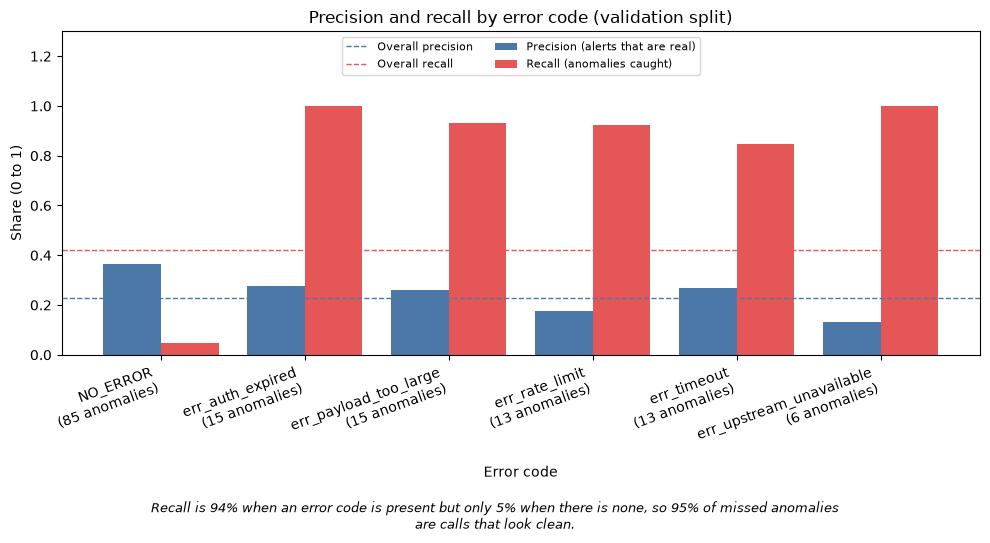

error_analysis_by_error_code.png: Recall is 94% when an error code is present but only 5% when there is none, so 95% of missed anomalies are calls that look clean.


In [8]:
def finish(fig, name, caption):
    """Add the takeaway caption under the figure, save it as a PNG and show it."""
    fig.text(0.5, -0.01, textwrap.fill(caption, 105), ha="center", va="top", fontsize=9, style="italic")
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"{name}: {caption}")


err = audit_table[audit_table["group"] == "error_code"].set_index("level")
order = ["NO_ERROR", *[c for c in err.index if c != "NO_ERROR"]]
err = err.loc[order]
pos_x = np.arange(len(err))
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(pos_x - 0.2, err["precision"], width=0.4, color="#4C78A8", label="Precision (alerts that are real)")
ax.bar(pos_x + 0.2, err["recall"], width=0.4, color="#E45756", label="Recall (anomalies caught)")
ax.axhline(overall_prec, color="#4C78A8", linestyle="--", linewidth=1, label="Overall precision")
ax.axhline(overall_rec, color="#E45756", linestyle="--", linewidth=1, label="Overall recall")
ax.set_xticks(pos_x)
ax.set_xticklabels(
    [f"{c}\n({int(a)} anomalies)" for c, a in zip(err.index, err["anomalies"], strict=False)],
    rotation=20,
    ha="right",
)
ax.set_ylim(0, 1.3)
ax.set_xlabel("Error code")
ax.set_ylabel("Share (0 to 1)")
ax.set_title("Precision and recall by error code (validation split)")
ax.legend(loc="upper center", ncol=2, fontsize=8)
fig.tight_layout()
finish(
    fig,
    "error_analysis_by_error_code.png",
    f"Recall is {caught_err:.0%} when an error code is present but only {caught_clean:.0%} when there is none, "
    f"so {(missed['has_error'] == 'no error').mean():.0%} of missed anomalies are calls that look clean.",
)

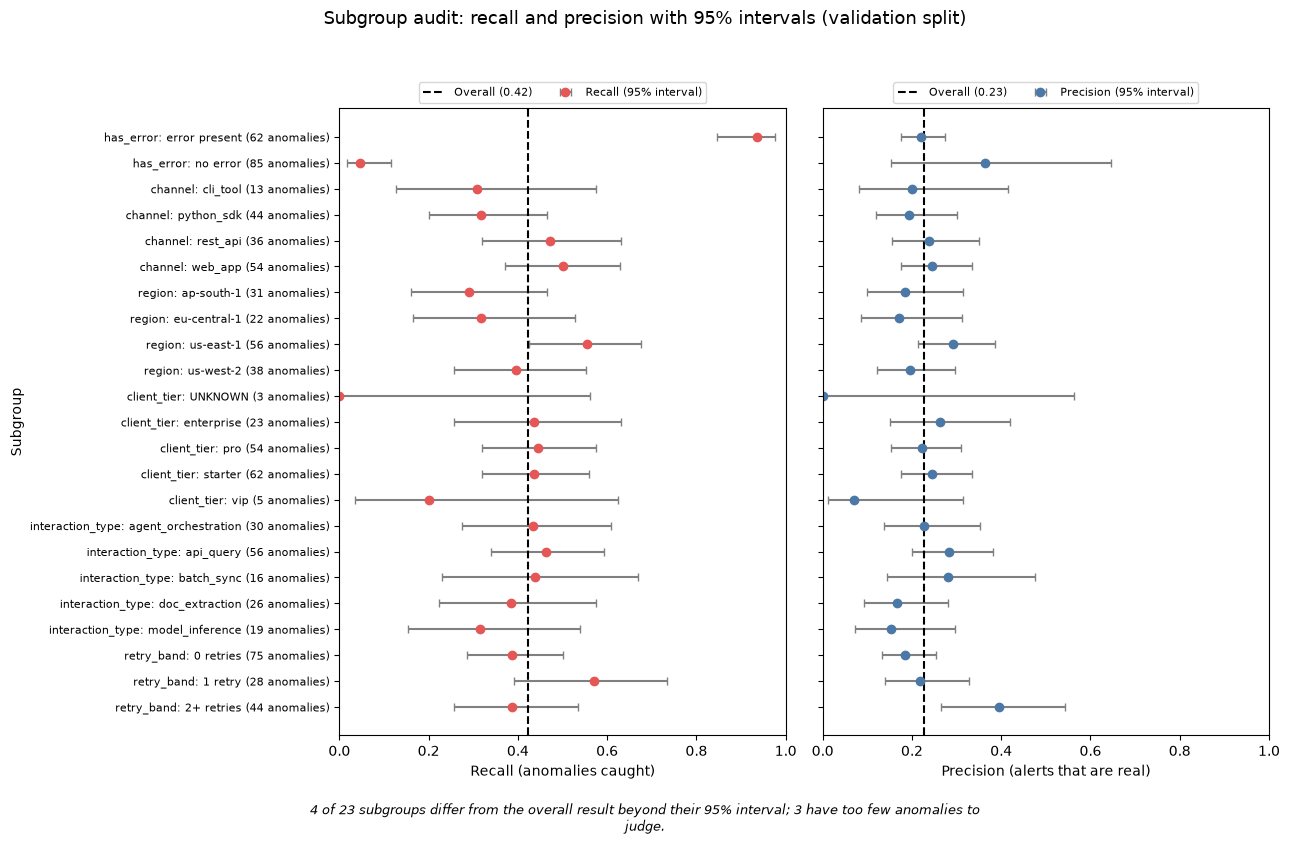

subgroup_audit.png: 4 of 23 subgroups differ from the overall result beyond their 95% interval; 3 have too few anomalies to judge.


,group,level,anomalies,precision,recall,verdict
0,has_error,error present,62,0.221,0.935,recall above overall
1,has_error,no error,85,0.364,0.047,recall below overall
8,region,us-east-1,56,0.292,0.554,recall above overall
22,retry_band,2+ retries,44,0.395,0.386,precision above overall


In [9]:
sub = audit_table[audit_table["group"] != "error_code"].reset_index(drop=True)
labels = [f"{g}: {lv} ({int(a)} anomalies)" for g, lv, a in zip(sub["group"], sub["level"], sub["anomalies"], strict=False)]
ypos = np.arange(len(sub))[::-1]
fig, axes = plt.subplots(1, 2, figsize=(13, 8), sharey=True)
for ax, metric, lo, hi, overall, color, name in (
    (axes[0], "recall", "rec lo", "rec hi", overall_rec, "#E45756", "Recall (anomalies caught)"),
    (axes[1], "precision", "prec lo", "prec hi", overall_prec, "#4C78A8", "Precision (alerts that are real)"),
):
    vals = sub[metric].to_numpy(dtype=float)
    err_lo = vals - sub[lo].to_numpy(dtype=float)
    err_hi = sub[hi].to_numpy(dtype=float) - vals
    ax.errorbar(vals, ypos, xerr=[err_lo, err_hi], fmt="o", color=color, ecolor="gray", capsize=3, label=f"{metric.capitalize()} (95% interval)")
    ax.axvline(overall, color="black", linestyle="--", label=f"Overall ({overall:.2f})")
    ax.set_xlabel(name)
    ax.set_xlim(0, 1)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=8)
axes[0].set_yticks(ypos)
axes[0].set_yticklabels(labels, fontsize=8)
axes[0].set_ylabel("Subgroup")
fig.suptitle("Subgroup audit: recall and precision with 95% intervals (validation split)", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.95])
flags = sub[~sub["verdict"].isin(["consistent with overall", "too few anomalies to judge"])]
finish(
    fig,
    "subgroup_audit.png",
    f"{len(flags)} of {len(sub)} subgroups differ from the overall result beyond their 95% interval; "
    f"{int((sub['verdict'] == 'too few anomalies to judge').sum())} have too few anomalies to judge.",
)
flags[["group", "level", "anomalies", "precision", "recall", "verdict"]]

## Findings
At the chosen threshold (0.1834) the model catches 62 anomalies, misses 85 and raises 211 false alarms: precision 0.227, recall 0.422 on the validation split.

1. **The model works almost entirely as an error-code detector.** Recall is 0.935 when an error code is present (62 anomalies) and 0.047 when there is none (85 anomalies). 95% of missed anomalies (81 of 85) have no error code, and 97% of false alarms carry one. The simple rule "alert whenever an error code is present" flags 299 calls with precision 0.207 and recall 0.422, against 0.227 and 0.422 for the model, so at this threshold the model adds only about 2 points of precision over that rule.
2. **58% of anomalies (85 of 147) carry no error code and are almost never caught.** Their features look normal: median payload 16.5 KB, latency 68.7 ms and 0 retries, against 16.0 KB, 70.6 ms and 0 retries for correctly ignored normal calls. With the current nine features there is nothing for the model to see in these calls.
3. **False alarms look like real anomalies.** Every one of the eight highest-scoring false alarms carries an error code, and 7 of the 8 have 3 retries. Rate-limit errors are over-represented among false alarms (26% of false alarms against 19% of caught anomalies), and err_rate_limit has precision 0.176 against 0.26 to 0.28 for auth_expired, payload_too_large and timeout. This suggests rate-limit retries are often harmless, but that group has only 13 anomalies, so it is a lead to check, not a conclusion.
4. **Subgroup audit:** 4 of 23 subgroups differ from the overall result beyond their 95% interval. Two are the error-present and no-error groups (expected). The third is calls with 2 or more retries, where precision is 0.395 against 0.227 overall (their anomaly rate is 9.5% against 3.9% overall). The fourth is region us-east-1, where recall is 0.554 against 0.422; its interval only just excludes the overall value, and with 46 intervals checked about two would be expected to do so by chance, so treat it as noise unless it repeats.
5. **No evidence of gaps** across channel, client tier or interaction type, but intervals are wide (13 to 62 anomalies per group), so this is absence of evidence, not proof of fairness. Three groups (cli_tool with 13 anomalies, client_tier UNKNOWN with 3 and vip with 5) have too few anomalies to judge.
6. **Calibration by group:** the mean calibrated score is close to the observed anomaly rate in most groups. The largest absolute gap is calls with 2 or more retries (mean score 0.074 against an observed 0.095), where the model under-predicts.

**Implication:** the model's skill comes from one column. Catching the anomalies that carry no error code needs information the current features do not contain, and it must be confirmed with the data owner whether error_code is known at the moment a call would be scored.

**Limitation:** the validation split holds only 147 anomalies, so every number above is noisy; the test split has not been touched.